# Chest X-ray Classification: Controlled Fine-tuning

Educational research only. Not for clinical use or diagnosis.

This notebook:
- Loads an existing trusted classification checkpoint.
- Uses the existing patient-level training/validation splits.
- Fine-tunes with a visible training loop.
- Selects checkpoints using validation macro average precision.
- Preserves the original deployed checkpoint.
- Does not use the test split.

Historical test-set influence on previous model choices is unknown.
This experiment cannot retroactively establish an untouched test set.

In [1]:
import json
import math
import os
import random
import subprocess
import sys
import time
from datetime import datetime, timezone
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
import yaml
from torch import nn
from torch.utils.data import DataLoader

candidates = [Path.cwd(), *Path.cwd().parents]
ROOT = next(
    (
        path
        for path in candidates
        if (path / "pyproject.toml").is_file()
        and (path / "ml/classification").is_dir()
    ),
    None,
)
if ROOT is None:
    raise RuntimeError("Open the notebook from inside the project repository.")

os.chdir(ROOT)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from ml.classification.dataset import LABEL_COLUMNS, ChestXrayDataset
from ml.classification.evaluate import load_model
from ml.classification.finetune import (
    EpochAugmentedDataset,
    atomic_save,
    validation_metrics,
    write_json,
)
from ml.classification.validate_checkpoint import sha256_file

expected_python = ROOT / ".venv/Scripts/python.exe"
assert Path(sys.executable).resolve() == expected_python.resolve(), (
    f"Wrong kernel: {sys.executable}"
)
assert torch.cuda.is_available(), "CUDA is unavailable in this notebook kernel."

device = torch.device("cuda")

print("Project:", ROOT)
print("Python:", sys.executable)
print("Torch:", torch.__version__)
print("CUDA runtime:", torch.version.cuda)
print("GPU:", torch.cuda.get_device_name(0))
print(
    "Total VRAM MiB:",
    round(torch.cuda.get_device_properties(0).total_memory / 1024**2, 1),
)

Project: d:\Nexvia-Internship\ai-assisted-medical-imaging
Python: d:\Nexvia-Internship\ai-assisted-medical-imaging\.venv\Scripts\python.exe
Torch: 2.7.1+cu118
CUDA runtime: 11.8
GPU: NVIDIA GeForce RTX 3050 6GB Laptop GPU
Total VRAM MiB: 6143.5


In [2]:
CONFIG_PATH = ROOT / "ml/classification/config.yaml"
SOURCE_CHECKPOINT = ROOT / "models/classification/best_classifier.pt"
BASELINE_PATH = ROOT / "reports/classification_validation_baseline_01.json"

RUN_ID = (
    datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ")
    + "_frozen_bn_stats"
)
OUTPUT_DIR = ROOT / "models/classification" / f"notebook_finetune_{RUN_ID}"

MAX_EPOCHS = 1
HOURS_BUDGET = 5.0
LEARNING_RATE = 2e-5
WEIGHT_DECAY = 0.01
PATIENCE = 2
SEED = 42

assert not OUTPUT_DIR.exists(), f"Run directory already exists: {OUTPUT_DIR}"
assert MAX_EPOCHS > 0 and HOURS_BUDGET > 0 and PATIENCE > 0
assert LEARNING_RATE > 0

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.benchmark = False
torch.backends.cudnn.deterministic = True

print("Output directory:", OUTPUT_DIR)
print("Additional epochs:", MAX_EPOCHS)
print("Scheduling budget, hours:", HOURS_BUDGET)
print("Learning rate:", LEARNING_RATE)
print("BatchNorm running statistics: frozen during training")

Output directory: d:\Nexvia-Internship\ai-assisted-medical-imaging\models\classification\notebook_finetune_20261109T190232Z_frozen_bn_stats
Additional epochs: 1
Scheduling budget, hours: 5.0
Learning rate: 2e-05
BatchNorm running statistics: frozen during training


In [3]:
config = yaml.safe_load(CONFIG_PATH.read_text(encoding="utf-8"))
baseline = json.loads(BASELINE_PATH.read_text(encoding="utf-8"))

manifest_path = Path(config["dataset"]["manifest_file"]).with_name(
    "nih_chestxray14_patient_splits.csv"
)

source_hash = sha256_file(SOURCE_CHECKPOINT)
manifest_hash = sha256_file(manifest_path)
config_hash = sha256_file(CONFIG_PATH)

checks = {
    "checkpoint_sha256": source_hash,
    "manifest_sha256": manifest_hash,
    "config_sha256": config_hash,
    "split": "validation",
}
for key, expected in checks.items():
    assert baseline.get(key) == expected, f"Baseline mismatch: {key}"

assert baseline["label_columns"] == list(LABEL_COLUMNS)

baseline_ap = float(baseline["macro_average_precision"])
assert math.isfinite(baseline_ap)

print("Baseline images:", baseline["validation_samples"])
print("Baseline macro AP:", baseline_ap)
print("Baseline macro AUROC:", baseline["macro_auroc"])
print("Source checkpoint SHA256:", source_hash)

Baseline images: 8182
Baseline macro AP: 0.225998
Baseline macro AUROC: 0.828013
Source checkpoint SHA256: 68a672938c24354b216e9c54f4441fae3545e46c7aa96f88ccd398621f1b65a5


In [4]:
image_config = config["image"]
dataset_settings = {
    "manifest_path": manifest_path,
    "image_size": (
        image_config["resize_width"],
        image_config["resize_height"],
    ),
    "mean": image_config["normalize_mean"],
    "std": image_config["normalize_std"],
    "augment": False,
}

train_dataset = EpochAugmentedDataset(
    split="train",
    seed=SEED,
    **dataset_settings,
)
validation_dataset = ChestXrayDataset(
    split="validation",
    **dataset_settings,
)

assert len(validation_dataset) == baseline["validation_samples"]

BATCH_SIZE = int(config["training"]["batch_size"])

# Notebook-safe starting setting on Windows. Measure before increasing.
NUM_WORKERS = 0

loader_settings = {
    "batch_size": BATCH_SIZE,
    "num_workers": NUM_WORKERS,
    "pin_memory": True,
}
train_loader = DataLoader(
    train_dataset,
    shuffle=True,
    generator=torch.Generator().manual_seed(SEED),
    **loader_settings,
)
validation_loader = DataLoader(
    validation_dataset,
    shuffle=False,
    **loader_settings,
)

model, source_checkpoint = load_model(SOURCE_CHECKPOINT, device)

stored_labels = source_checkpoint.get("label_columns")
if stored_labels is not None:
    assert list(stored_labels) == list(LABEL_COLUMNS)

del source_checkpoint


def freeze_batchnorm_running_stats(model):
    """Put BatchNorm modules in evaluation mode.

    This keeps their stored running mean/variance fixed during subsequent
    training forward passes. Their affine weight and bias remain trainable.
    Call this after model.train(), because model.train() resets module modes.
    """
    batchnorm_classes = (
        nn.BatchNorm1d,
        nn.BatchNorm2d,
        nn.BatchNorm3d,
    )
    frozen_count = 0

    for module in model.modules():
        if isinstance(module, batchnorm_classes):
            module.eval()
            frozen_count += 1

    return frozen_count


BN_FROZEN_COUNT = freeze_batchnorm_running_stats(model)
assert BN_FROZEN_COUNT > 0, "No BatchNorm modules were found."

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY,
)
criterion = nn.BCEWithLogitsLoss()
scaler = torch.amp.GradScaler("cuda")

print("Train images:", len(train_dataset))
print("Validation images:", len(validation_dataset))
print("Batches per training epoch:", len(train_loader))
print("Batch size:", BATCH_SIZE)
print("DataLoader workers:", NUM_WORKERS)
print("BatchNorm modules with frozen running statistics:", BN_FROZEN_COUNT)
print("Model loaded from existing trained checkpoint.")

Train images: 78342
Validation images: 8182
Batches per training epoch: 4897
Batch size: 16
DataLoader workers: 0
BatchNorm modules with frozen running statistics: 121
Model loaded from existing trained checkpoint.


In [5]:
OUTPUT_DIR.mkdir(parents=True, exist_ok=False)

revision = subprocess.run(
    ["git", "rev-parse", "HEAD"],
    check=True,
    capture_output=True,
    text=True,
).stdout.strip()

git_status = subprocess.run(
    ["git", "status", "--porcelain"],
    check=True,
    capture_output=True,
    text=True,
).stdout

tracked_sources = [
    "ml/classification/finetune.py",
    "ml/classification/dataset.py",
    "ml/classification/preprocessing.py",
    "ml/classification/pilot.py",
    "ml/classification/evaluate.py",
]

metadata = {
    "entry_point": "ml/notebooks/04_classification_finetuning.ipynb",
    "recorded_at_utc": datetime.now(timezone.utc).isoformat(),
    "git_revision": revision,
    "git_status": git_status,
    "python": sys.version,
    "torch": str(torch.__version__),
    "gpu": torch.cuda.get_device_name(0),
    "config_snapshot": config,
    "source_checkpoint_sha256": source_hash,
    "manifest_sha256": manifest_hash,
    "config_sha256": config_hash,
    "baseline_report_sha256": sha256_file(BASELINE_PATH),
    "seed": SEED,
    "learning_rate": LEARNING_RATE,
    "weight_decay": WEIGHT_DECAY,
    "max_additional_epochs": MAX_EPOCHS,
    "hours_budget": HOURS_BUDGET,
    "patience": PATIENCE,
    "batch_size": BATCH_SIZE,
    "num_workers": NUM_WORKERS,
    "batchnorm_running_stats": "frozen_during_training",
    "batchnorm_frozen_module_count": BN_FROZEN_COUNT,
    "selection_metric": "validation_macro_average_precision",
    "source_hashes": {
        path: sha256_file(ROOT / path) for path in tracked_sources
    },
}

write_json(OUTPUT_DIR / "run_config.json", metadata)
write_json(OUTPUT_DIR / "baseline_validation.json", baseline)

BEST_PATH = OUTPUT_DIR / "best_classifier.pt"

atomic_save(
    {
        "epoch": 0,
        "model_state_dict": model.state_dict(),
        "label_columns": list(LABEL_COLUMNS),
        "validation_macro_average_precision": baseline_ap,
        "origin": "unchanged_baseline",
        "source_checkpoint_sha256": source_hash,
    },
    BEST_PATH,
)

history = []
best_ap = baseline_ap
best_epoch = 0
non_improving = 0
training_started = False

print("Run directory created:", OUTPUT_DIR)
print("Baseline weights preserved as initial best.")
print("BatchNorm running statistics will remain frozen during training.")
print("Save the notebook now using Ctrl+S before starting training.")

Run directory created: d:\Nexvia-Internship\ai-assisted-medical-imaging\models\classification\notebook_finetune_20261109T190232Z_frozen_bn_stats
Baseline weights preserved as initial best.
BatchNorm running statistics will remain frozen during training.
Save the notebook now using Ctrl+S before starting training.


In [6]:
assert not training_started, (
    "This training cell has already started. Do not rerun it as a fresh run."
)
training_started = True

started = time.perf_counter()
deadline = started + HOURS_BUDGET * 3600
previous_epoch_seconds = None
stop_reason = "epoch_limit"

try:
    for epoch in range(1, MAX_EPOCHS + 1):
        remaining = deadline - time.perf_counter()

        if remaining <= 0 or (
            previous_epoch_seconds is not None
            and remaining < previous_epoch_seconds * 1.15
        ):
            stop_reason = "insufficient_budget_for_another_epoch"
            break

        epoch_started = time.perf_counter()
        train_dataset.epoch = epoch

        model.train()
        frozen_batchnorm_count = freeze_batchnorm_running_stats(model)
        assert frozen_batchnorm_count == BN_FROZEN_COUNT

        torch.cuda.reset_peak_memory_stats()

        loss_sum = 0.0
        samples_seen = 0
        budget_reached = False

        for batch_index, (images, targets) in enumerate(train_loader, start=1):
            if time.perf_counter() >= deadline:
                budget_reached = True
                break

            images = images.to(device, non_blocking=True)
            targets = targets.to(device, non_blocking=True)

            optimizer.zero_grad(set_to_none=True)

            with torch.autocast(device_type="cuda"):
                logits = model(images)
                loss = criterion(logits, targets)

            if not torch.isfinite(loss).item():
                raise RuntimeError("Non-finite loss. Stopping experiment.")

            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            scaler.step(optimizer)
            scaler.update()

            batch_size = targets.shape[0]
            loss_sum += loss.item() * batch_size
            samples_seen += batch_size

            if batch_index % 100 == 0:
                elapsed = time.perf_counter() - epoch_started
                print(
                    f"Epoch {epoch}/{MAX_EPOCHS} | "
                    f"Batch {batch_index}/{len(train_loader)} | "
                    f"Loss {loss_sum / samples_seen:.5f} | "
                    f"Images/s {samples_seen / elapsed:.2f}",
                    flush=True,
                )

        if budget_reached:
            stop_reason = "budget_reached_partial_epoch_not_selected"
            break

        metrics = validation_metrics(model, validation_loader, device)
        current_ap = metrics["macro_average_precision"]

        if current_ap is None or not math.isfinite(float(current_ap)):
            raise RuntimeError("Validation macro AP is undefined.")

        improved = float(current_ap) > best_ap

        if improved:
            best_ap = float(current_ap)
            best_epoch = epoch
            non_improving = 0
        else:
            non_improving += 1

        scaler_state = scaler.state_dict()

        checkpoint = {
            "epoch": epoch,
            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "scaler_state_dict": scaler_state,
            "label_columns": list(LABEL_COLUMNS),
            "validation_macro_average_precision": float(current_ap),
            "best_validation_macro_average_precision": best_ap,
            "origin": "notebook_finetuned_candidate_frozen_bn_stats",
            "source_checkpoint_sha256": source_hash,
        }

        atomic_save(checkpoint, OUTPUT_DIR / "last_classifier.pt")

        if improved:
            atomic_save(checkpoint, BEST_PATH)
            write_json(OUTPUT_DIR / "best_validation.json", metrics)

        write_json(
            OUTPUT_DIR / f"validation_epoch_{epoch:02d}.json",
            metrics,
        )

        previous_epoch_seconds = time.perf_counter() - epoch_started

        record = {
            "epoch": epoch,
            "train_loss": loss_sum / samples_seen,
            "validation_macro_ap": float(current_ap),
            "validation_macro_auroc": metrics["macro_auroc"],
            "improved": improved,
            "batchnorm_running_stats": "frozen_during_training",
            "frozen_batchnorm_module_count": frozen_batchnorm_count,
            "elapsed_seconds": round(previous_epoch_seconds, 3),
            "peak_allocated_mib": round(
                torch.cuda.max_memory_allocated() / 1024**2, 2
            ),
        }

        history.append(record)

        with (OUTPUT_DIR / "training_log.jsonl").open(
            "a", encoding="utf-8"
        ) as handle:
            handle.write(json.dumps(record, allow_nan=False) + "\n")

        print("\nEPOCH RESULT:", json.dumps(record), "\n", flush=True)

        if non_improving >= PATIENCE:
            stop_reason = "early_stopping"
            break

except KeyboardInterrupt:
    stop_reason = "manually_interrupted_partial_epoch_not_selected"
    print("Interrupted. Previously saved validated checkpoints are preserved.")

except Exception:
    stop_reason = "error_check_traceback"
    raise

finally:
    summary = {
        "completed_additional_epochs": len(history),
        "best_additional_epoch": best_epoch,
        "baseline_validation_macro_ap": baseline_ap,
        "best_validation_macro_ap": best_ap,
        "improved_over_baseline": best_epoch > 0,
        "best_checkpoint": BEST_PATH.as_posix(),
        "best_checkpoint_sha256": sha256_file(BEST_PATH),
        "stop_reason": stop_reason,
        "batchnorm_running_stats": "frozen_during_training",
        "elapsed_seconds": round(time.perf_counter() - started, 3),
    }

    write_json(OUTPUT_DIR / "summary.json", summary)
    print(json.dumps(summary, indent=2))

Epoch 1/1 | Batch 100/4897 | Loss 0.13114 | Images/s 23.29
Epoch 1/1 | Batch 200/4897 | Loss 0.12599 | Images/s 24.19
Epoch 1/1 | Batch 300/4897 | Loss 0.12737 | Images/s 24.00
Epoch 1/1 | Batch 400/4897 | Loss 0.12643 | Images/s 23.67
Epoch 1/1 | Batch 500/4897 | Loss 0.12747 | Images/s 23.12
Epoch 1/1 | Batch 600/4897 | Loss 0.12790 | Images/s 22.79
Epoch 1/1 | Batch 700/4897 | Loss 0.12853 | Images/s 22.65
Epoch 1/1 | Batch 800/4897 | Loss 0.12781 | Images/s 22.91
Epoch 1/1 | Batch 900/4897 | Loss 0.12740 | Images/s 22.86
Epoch 1/1 | Batch 1000/4897 | Loss 0.12746 | Images/s 23.05
Epoch 1/1 | Batch 1100/4897 | Loss 0.12716 | Images/s 23.18
Epoch 1/1 | Batch 1200/4897 | Loss 0.12710 | Images/s 23.17
Epoch 1/1 | Batch 1300/4897 | Loss 0.12721 | Images/s 22.44
Epoch 1/1 | Batch 1400/4897 | Loss 0.12741 | Images/s 22.03
Epoch 1/1 | Batch 1500/4897 | Loss 0.12720 | Images/s 21.57
Epoch 1/1 | Batch 1600/4897 | Loss 0.12681 | Images/s 21.18
Epoch 1/1 | Batch 1700/4897 | Loss 0.12664 | Imag

{
  "completed_additional_epochs": 1,
  "best_additional_epoch": 1,
  "baseline_validation_macro_ap": 0.225998,
  "best_validation_macro_ap": 0.25055,
  "improved_over_baseline": true,
  "best_checkpoint": "d:/Nexvia-Internship/ai-assisted-medical-imaging/models/classification/notebook_finetune_20261109T190232Z_frozen_bn_stats/best_classifier.pt",
  "best_checkpoint_sha256": "e887c2b143297ce58924bf016f51ea6e6bf1210edf649b4cc6cbb453bb0fec31",
  "stop_reason": "epoch_limit",
  "batchnorm_running_stats": "frozen_during_training",
  "elapsed_seconds": 4702.426
}


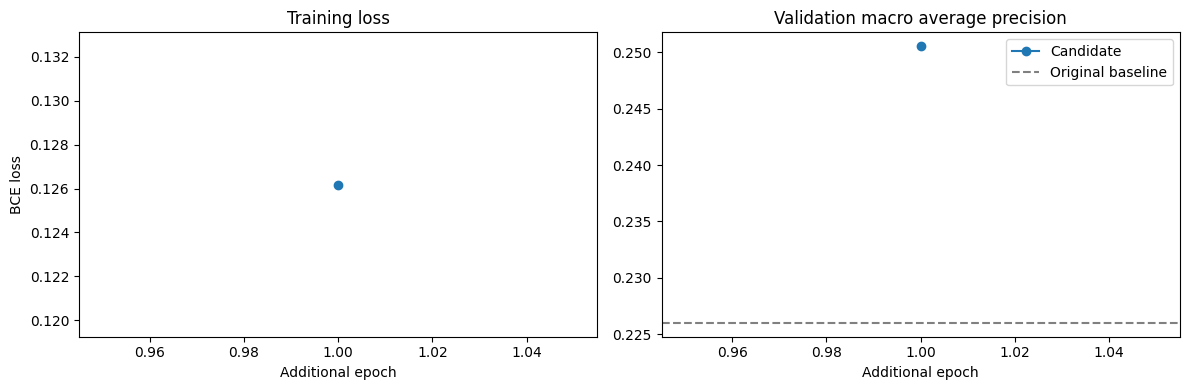

In [7]:
summary = json.loads(
    (OUTPUT_DIR / "summary.json").read_text(encoding="utf-8")
)
print(json.dumps(summary, indent=2))

if history:
    epoch_numbers = [row["epoch"] for row in history]

    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    axes[0].plot(
        epoch_numbers,
        [row["train_loss"] for row in history],
        marker="o",
    )
    axes[0].set_title("Training loss")
    axes[0].set_xlabel("Additional epoch")
    axes[0].set_ylabel("BCE loss")

    axes[1].plot(
        epoch_numbers,
        [row["validation_macro_ap"] for row in history],
        marker="o",
        label="Candidate",
    )
    axes[1].axhline(
        baseline_ap,
        color="gray",
        linestyle="--",
        label="Original baseline",
    )
    axes[1].set_title("Validation macro average precision")
    axes[1].set_xlabel("Additional epoch")
    axes[1].legend()

    fig.tight_layout()
    fig.savefig(OUTPUT_DIR / "training_curves.png", dpi=150)
    plt.show()
else:
    print("No complete training + validation epoch was recorded.")

In [8]:
from ml.classification.validate_checkpoint import validate_checkpoint

verified_best = validate_checkpoint(
    config_path=CONFIG_PATH,
    checkpoint_path=BEST_PATH,
    output_path=OUTPUT_DIR / "selected_checkpoint_validation.json",
)

print("Original validation AP:", baseline_ap)
print("Selected validation AP:", verified_best["macro_average_precision"])
print("Selected validation AUROC:", verified_best["macro_auroc"])

Validating d:\Nexvia-Internship\ai-assisted-medical-imaging\models\classification\notebook_finetune_20261109T190232Z_frozen_bn_stats\best_classifier.pt on 8182 images using cuda.
Original validation AP: 0.225998
Selected validation AP: 0.25055
Selected validation AUROC: 0.840417


In [9]:
import json
import os
import sys
from pathlib import Path

import torch

roots = [Path.cwd(), *Path.cwd().parents]
project_root = next(
    (
        path
        for path in roots
        if (path / "pyproject.toml").is_file()
        and (path / "ml/classification").is_dir()
    ),
    None,
)
if project_root is None:
    raise RuntimeError("Cannot locate the project root.")

os.chdir(project_root)
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from ml.classification.evaluate import load_model
from ml.classification.validate_checkpoint import (
    sha256_file,
    validate_checkpoint,
)

run_directory = project_root / (
    "models/classification/notebook_finetune_20261109T120835Z"
)
original_path = project_root / "models/classification/best_classifier.pt"
epoch2_path = run_directory / "last_classifier.pt"
temporary_path = run_directory / "diagnostic_bn_baseline_stats.pt"
report_path = run_directory / "diagnostic_bn_baseline_stats_validation.json"

if temporary_path.exists() or report_path.exists():
    raise FileExistsError(
        "Diagnostic output already exists. Do not overwrite; inspect it first."
    )

baseline_report = json.loads(
    (run_directory / "baseline_validation.json").read_text(encoding="utf-8")
)
assert sha256_file(original_path) == baseline_report["checkpoint_sha256"]
assert torch.cuda.is_available(), "CUDA is unavailable."

diagnostic_device = torch.device("cpu")
baseline_model, baseline_checkpoint = load_model(
    original_path, diagnostic_device
)
candidate_model, candidate_checkpoint = load_model(
    epoch2_path, diagnostic_device
)
assert int(candidate_checkpoint["epoch"]) == 2

baseline_buffers = dict(baseline_model.named_buffers())
replacement_count = 0

with torch.no_grad():
    for name, module in candidate_model.named_modules():
        if not isinstance(module, torch.nn.modules.batchnorm._BatchNorm):
            continue

        for field in ("running_mean", "running_var", "num_batches_tracked"):
            candidate_buffer = getattr(module, field, None)
            if candidate_buffer is None:
                continue

            key = f"{name}.{field}" if name else field
            baseline_buffer = baseline_buffers[key]
            assert candidate_buffer.shape == baseline_buffer.shape
            candidate_buffer.copy_(baseline_buffer)
            replacement_count += 1

assert replacement_count > 0, "No BatchNorm buffers were replaced."

diagnostic_checkpoint = {
    "epoch": 2,
    "model_state_dict": candidate_model.state_dict(),
    "label_columns": candidate_checkpoint["label_columns"],
    "origin": "DIAGNOSTIC_ONLY_epoch2_weights_with_baseline_bn_buffers",
    "baseline_checkpoint_sha256": sha256_file(original_path),
    "epoch2_checkpoint_sha256": sha256_file(epoch2_path),
}

try:
    torch.save(diagnostic_checkpoint, temporary_path)

    del baseline_checkpoint, candidate_checkpoint
    del baseline_model, candidate_model, diagnostic_checkpoint

    diagnostic_result = validate_checkpoint(
        config_path=project_root / "ml/classification/config.yaml",
        checkpoint_path=temporary_path,
        output_path=report_path,
    )
finally:
    if temporary_path.exists():
        temporary_path.unlink()

epoch2_report = json.loads(
    (run_directory / "validation_epoch_02.json").read_text(encoding="utf-8")
)

print("Replaced BatchNorm buffers:", replacement_count)
print()
print("Baseline AP:", baseline_report["macro_average_precision"])
print("Epoch-2 AP:", epoch2_report["macro_average_precision"])
print("Diagnostic AP:", diagnostic_result["macro_average_precision"])
print()
print("Baseline AUROC:", baseline_report["macro_auroc"])
print("Epoch-2 AUROC:", epoch2_report["macro_auroc"])
print("Diagnostic AUROC:", diagnostic_result["macro_auroc"])
print()
print("Diagnostic report:", report_path)
print("Temporary diagnostic checkpoint removed; original files unchanged.")

FileExistsError: Diagnostic output already exists. Do not overwrite; inspect it first.

In [ ]:
import json
from pathlib import Path

root = next(
    (
        path
        for path in [Path.cwd(), *Path.cwd().parents]
        if (path / "pyproject.toml").is_file()
        and (path / "ml/classification").is_dir()
    ),
    None,
)
if root is None:
    raise RuntimeError("Project root not found.")

run_dir = root / "models/classification/notebook_finetune_20261109T120835Z"
baseline = json.loads(
    (run_dir / "baseline_validation.json").read_text(encoding="utf-8")
)
diagnostic = json.loads(
    (run_dir / "diagnostic_bn_baseline_stats_validation.json").read_text(
        encoding="utf-8"
    )
)

print(
    f"{'Label':<20} {'N+':>5} {'Base AP':>9} {'Diag AP':>9} "
    f"{'AP delta':>10} {'AUC delta':>10}"
)

for label, original in baseline["per_label"].items():
    candidate = diagnostic["per_label"][label]

    def format_value(value):
        return "NA" if value is None else f"{value:.6f}"

    def delta(new, old):
        return None if new is None or old is None else new - old

    print(
        f"{label:<20} {original['support_positive']:>5} "
        f"{format_value(original['average_precision']):>9} "
        f"{format_value(candidate['average_precision']):>9} "
        f"{format_value(delta(candidate['average_precision'], original['average_precision'])):>10} "
        f"{format_value(delta(candidate['auroc'], original['auroc'])):>10}"
    )